# 4.1 Tariffs and demand models: 2023

**Question.** How does gas demand respond to weather, how well can monthly electricity demand be predicted, and how much would SERL households have paid in 2023 on a dynamic tariff (Octopus Agile) compared with a flat one?

**Data.** SERL cleaned daily-statistics file (monthly rows) and the 2023 half-hourly file (`serl_energy.dataset`); published Octopus prices from the public API (`serl_energy.tariffs`, cached in `data/external/octopus/`; the code stops with an error rather than invent prices).

**Method.**
1. **Gas and weather:** Bayesian regression (PyMC, NUTS, 4 chains) of monthly gas use on heating degree days and solar irradiance, gas-heated homes in each region, with partially pooled region intercepts.
2. **Monthly electricity:** linear regression, random forest and gradient boosting on weather, calendar and region, trained on 2020–2022 and tested on 2023, against seasonal naive.
3. **Tariffs, 2023:** SERL half-hourly shapes × monthly levels priced on Agile and Flexible Octopus, with load shifting, household groups and regions.

**Where the other tariff results are.** 4.2 covers 2022–2024, the energy-poverty scenarios (flexibility and access gaps) and the 2022 crisis; this notebook covers 2023 by quarter, group and region.

**Outputs.** Figures in `reports/figures/4.1-tariffs-demand-models/`, tables in `reports/tables/4.1-tariffs-demand-models/`.


## 1. Gas demand and weather (Bayesian regression)

**Data:** monthly mean gas use (kWh/day) of gas-heated homes without PV, in each of the 11 regions, 2020–2023 (528 region-months), with SERL's region-matched heating degree days (HDD) and solar irradiance.

**Model:** gas = region intercept + β_HDD · HDD + β_solar · solar + noise. Region intercepts share a common prior (partial pooling). Predictors are standardised for sampling; the HDD effect is reported back in kWh/day per degree-day. Temperature is left out because it mirrors HDD (correlation −0.99), which would make both coefficients uninterpretable.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

from serl_energy import dataset as serl, plots, tariffs
from serl_energy.labels import group_label, role
from serl_energy.plots import COLORS, INK, ROLE_COLORS, SEQUENTIAL_CMAP
from serl_energy.reporting import Reporter

warnings.filterwarnings("ignore", category=FutureWarning)
plots.use_theme()
reporter = Reporter("4.1-tariffs-demand-models")

monthly = serl.load_monthly(serl.CLEAN_CSV)
SLICE = dict(quantity="Gas", unit="kWh/day", fuel="Gas", pv="No")
panels = {v: serl.monthly_panel(monthly, segment="region", value=v, **SLICE) for v in ("mean", "mean_hdd", "mean_solar")}
long = pd.concat({k: p.stack() for k, p in panels.items()}, axis=1).reset_index()
long.columns = ["date", "region", "gas", "hdd", "solar"]
regions = sorted(long["region"].unique())
region_idx = long["region"].map({r: i for i, r in enumerate(regions)}).to_numpy()
hdd_mu, hdd_sd = long["hdd"].mean(), long["hdd"].std()
sol_mu, sol_sd = long["solar"].mean(), long["solar"].std()
hdd_z = ((long["hdd"] - hdd_mu) / hdd_sd).to_numpy()
sol_z = ((long["solar"] - sol_mu) / sol_sd).to_numpy()
print(f"{len(long)} region-months; gas {long['gas'].min():.1f}–{long['gas'].max():.1f} kWh/day")

with pm.Model(coords={"region": regions}) as gas_model:
    mu_alpha = pm.Normal("mu_alpha", mu=long["gas"].mean(), sigma=20)
    sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=10)
    alpha = pm.Normal("alpha", mu=mu_alpha, sigma=sigma_alpha, dims="region")
    beta_hdd = pm.Normal("beta_hdd", mu=0, sigma=20)
    beta_solar = pm.Normal("beta_solar", mu=0, sigma=20)
    sigma = pm.HalfNormal("sigma", sigma=10)
    mu = alpha[region_idx] + beta_hdd * hdd_z + beta_solar * sol_z
    pm.Normal("gas", mu=mu, sigma=sigma, observed=long["gas"].to_numpy())
    trace = pm.sample(1000, tune=1000, chains=4, cores=1, target_accept=0.9, random_seed=42, progressbar=False)
    ppc = pm.sample_posterior_predictive(trace, random_seed=42, progressbar=False)

summary = az.summary(trace, var_names=["mu_alpha", "sigma_alpha", "beta_hdd", "beta_solar", "sigma"], hdi_prob=0.94)
print(summary.round(3).to_string())
full = az.summary(trace, hdi_prob=0.94)
print(f"\nConvergence: max r_hat = {full['r_hat'].max():.3f}, min bulk ESS = {full['ess_bulk'].min():.0f} (4 chains x 1000 draws)")
per_dd = trace.posterior["beta_hdd"] / hdd_sd
lo, hi = az.hdi(per_dd, hdi_prob=0.94)["beta_hdd"].to_numpy()
print(f"Each extra heating degree-day per day adds {float(per_dd.mean()):.2f} kWh/day of gas (94% HDI {lo:.2f} to {hi:.2f}).")
pred = ppc.posterior_predictive["gas"].stack(sample=("chain", "draw")).to_numpy().T
r2 = az.r2_score(long["gas"].to_numpy(), pred)
print(f"Bayesian R² = {r2['r2']:.3f} (sd {r2['r2_std']:.3f})")

table = full.rename(columns={"hdi_3%": "hdi_3_pct", "hdi_97%": "hdi_97_pct"})
table.index = [i.replace("alpha[", "alpha_").rstrip("]").replace(" ", "_").lower() for i in table.index]
table.index.name = "parameter"
reporter.save_table(table, "gas_weather_bayes_summary", index=True)

Initializing NUTS using jitter+adapt_diag...


528 region-months; gas 5.2–85.6 kWh/day


Sequential sampling (4 chains in 1 job)


NUTS: [mu_alpha, sigma_alpha, alpha, beta_hdd, beta_solar, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 5 seconds.


Sampling: [gas]


               mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
mu_alpha     33.357  1.172  30.996   35.489      0.020    0.025    3776.0    2651.0    1.0
sigma_alpha   3.682  1.008   2.115    5.565      0.017    0.026    4451.0    2771.0    1.0
beta_hdd     18.937  0.290  18.398   19.481      0.005    0.004    3631.0    3215.0    1.0
beta_solar   -4.639  0.287  -5.195   -4.107      0.005    0.004    3711.0    3267.0    1.0
sigma         4.744  0.148   4.471    5.030      0.002    0.003    6268.0    2518.0    1.0

Convergence: max r_hat = 1.000, min bulk ESS = 3631 (4 chains x 1000 draws)
Each extra heating degree-day per day adds 5.21 kWh/day of gas (94% HDI 5.06 to 5.36).
Bayesian R² = 0.920 (sd 0.005)


Left: every region-month with the posterior mean line and its 94% interval for the average region. Right: each region's intercept (gas use at average weather) with its 94% interval, labelled from the model's own region coordinates.


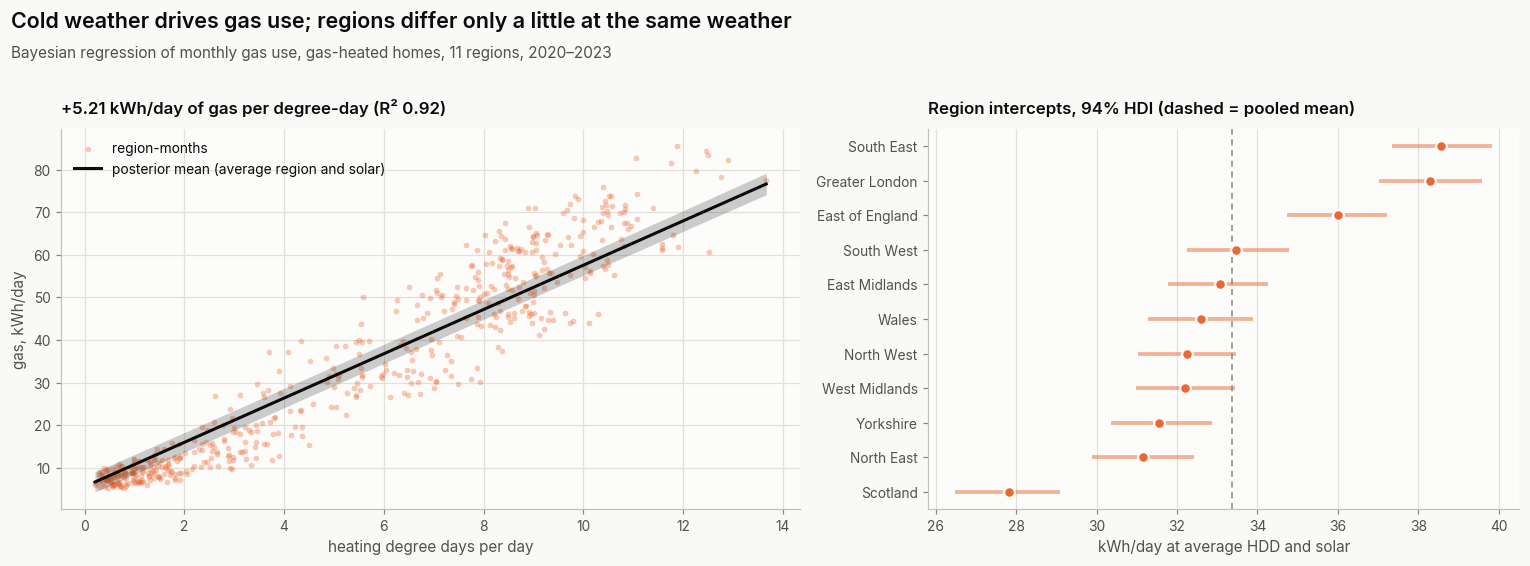

In [2]:
post = trace.posterior
grid = np.linspace(long["hdd"].min(), long["hdd"].max(), 60)
draws = (post["mu_alpha"].values.reshape(-1, 1)
         + post["beta_hdd"].values.reshape(-1, 1) * ((grid - hdd_mu) / hdd_sd))
band = np.percentile(draws, [3, 97], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.scatter(long["hdd"], long["gas"], s=14, color=COLORS["gas"], alpha=0.35, lw=0, label="region-months")
ax.fill_between(grid, band[0], band[1], color=INK["primary"], alpha=0.2, lw=0)
ax.plot(grid, draws.mean(axis=0), color=INK["primary"], lw=2, label="posterior mean (average region and solar)")
ax.set_xlabel("heating degree days per day"); ax.set_ylabel("gas, kWh/day"); ax.legend(loc="upper left")
ax.set_title(f"+{float(per_dd.mean()):.2f} kWh/day of gas per degree-day (R² {r2['r2']:.2f})", loc="left", fontsize=11)

ax = axes[1]
alpha_hdi = az.hdi(post["alpha"], hdi_prob=0.94)["alpha"].to_pandas()
forest = pd.DataFrame({"mean": post["alpha"].mean(("chain", "draw")).to_pandas(),
                       "lo": alpha_hdi["lower"], "hi": alpha_hdi["higher"]}).sort_values("mean")
pos = np.arange(len(forest))
ax.hlines(pos, forest["lo"], forest["hi"], color=COLORS["gas"], lw=2.5, alpha=0.5)
ax.scatter(forest["mean"], pos, color=COLORS["gas"], s=50, zorder=3, edgecolor=COLORS["surface"], linewidth=1.5)
ax.axvline(float(post["mu_alpha"].mean()), color=INK["muted"], lw=1, ls=(0, (4, 3)))
ax.set_yticks(pos, forest.index); ax.grid(axis="y", visible=False); ax.set_xlabel("kWh/day at average HDD and solar")
ax.set_title("Region intercepts, 94% HDI (dashed = pooled mean)", loc="left", fontsize=11)
plots.figure_title(fig, "Cold weather drives gas use; regions differ only a little at the same weather",
                   "Bayesian regression of monthly gas use, gas-heated homes, 11 regions, 2020–2023")
reporter.save_fig(fig, "gas-weather-bayes")
plt.show()

## 2. Predicting monthly electricity demand

**Data:** monthly mean electricity imports (kWh/day), all households in each region, 2020–2023. **Features:** heating degree days, solar irradiance, month of year (sine/cosine), a time index and region. **Split by time:** train on 2020–2022, test on all of 2023, so the test is a genuine forecast of an unseen year (a random split would let the models see 2023 neighbours of each test month).


train: 396 region-months (2020–2022), test: 132 (2023)



2023 test set (kWh/day; positive bias = over-forecast)
            model   mae  rmse  mape_pct  mean_bias
Gradient boosting 0.398 0.501     4.659      0.312
   Seasonal naive 0.414 0.541     4.710      0.257
    Random forest 0.541 0.661     6.555      0.374
Linear regression 0.678 0.825     8.495     -0.456



Permutation importance on the 2023 test set (Gradient boosting; increase in MAE when a feature is shuffled)
hdd          0.889
region       0.225
solar        0.120
month_cos    0.024
t            0.000
month_sin   -0.000


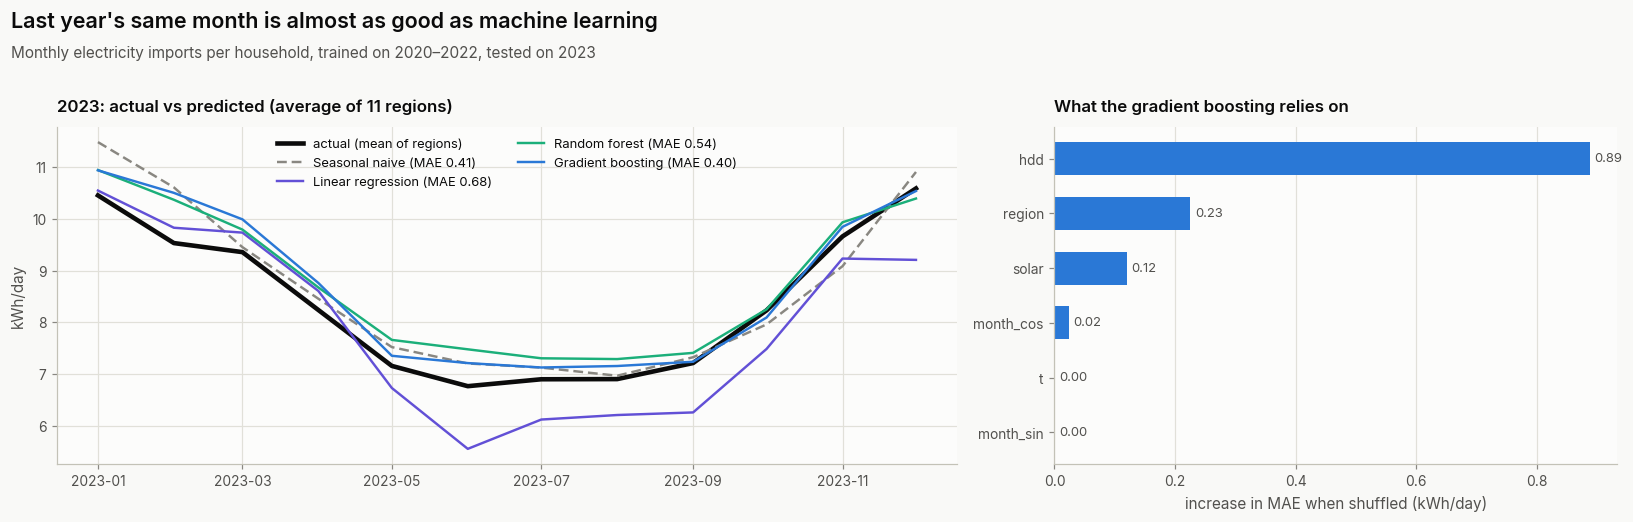

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

E = dict(quantity="Electricity imports", unit="kWh/day")
cols = {v: serl.monthly_panel(monthly, segment="region", value=v, **E) for v in ("mean", "mean_hdd", "mean_solar")}
data = pd.concat({k: p.stack() for k, p in cols.items()}, axis=1).reset_index()
data.columns = ["date", "region", "y", "hdd", "solar"]
data["month_sin"] = np.sin(2 * np.pi * data["date"].dt.month / 12)
data["month_cos"] = np.cos(2 * np.pi * data["date"].dt.month / 12)
data["t"] = (data["date"].dt.year - 2020) * 12 + data["date"].dt.month - 1
X = pd.concat([data[["hdd", "solar", "month_sin", "month_cos", "t"]],
               pd.get_dummies(data["region"], prefix="region", drop_first=True, dtype=float)], axis=1)
train, test = data["date"] < "2023-01-01", data["date"] >= "2023-01-01"
print(f"train: {train.sum()} region-months (2020–2022), test: {test.sum()} (2023)")

last_year = data.set_index(["region", "date"])["y"]
naive = [last_year[(r, d - pd.DateOffset(years=1))] for r, d in zip(data.loc[test, "region"], data.loc[test, "date"])]
preds = {"Seasonal naive": np.array(naive)}
fitted = {"Linear regression": LinearRegression(),
          "Random forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=42),
          "Gradient boosting": GradientBoostingRegressor(random_state=42)}
for name, model in fitted.items():
    model.fit(X[train], data.loc[train, "y"])
    preds[name] = model.predict(X[test])

y_test = data.loc[test, "y"].to_numpy()
results = pd.DataFrame([{"model": name, "mae": np.mean(np.abs(y_test - p)), "rmse": np.sqrt(np.mean((y_test - p) ** 2)),
                         "mape_pct": 100 * np.mean(np.abs(y_test - p) / y_test), "mean_bias": np.mean(p - y_test)}
                        for name, p in preds.items()]).sort_values("mae")
print("\n2023 test set (kWh/day; positive bias = over-forecast)")
print(results.round(3).to_string(index=False))
reporter.save_table(results, "ml_2023_test_results")

best_tree = min(["Random forest", "Gradient boosting"], key=lambda n: results.set_index("model").loc[n, "mae"])
imp = permutation_importance(fitted[best_tree], X[test], y_test, n_repeats=20, random_state=42)
importance = (pd.Series(imp.importances_mean, index=X.columns)
              .groupby(lambda c: "region" if c.startswith("region_") else c).sum().sort_values())
print(f"\nPermutation importance on the 2023 test set ({best_tree}; increase in MAE when a feature is shuffled)")
print(importance[::-1].round(3).to_string())

MODEL_COLORS = {"Seasonal naive": INK["muted"], "Linear regression": plots.CATEGORICAL[6],
                "Random forest": plots.CATEGORICAL[2], "Gradient boosting": COLORS["electricity"]}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
monthly_mean = data[test].assign(**{n: p for n, p in preds.items()}).groupby("date")[["y", *preds]].mean()
ax.plot(monthly_mean.index, monthly_mean["y"], color=INK["primary"], lw=3, label="actual (mean of regions)")
for n, color in MODEL_COLORS.items():
    ax.plot(monthly_mean.index, monthly_mean[n], color=color, lw=1.6, ls=(0, (4, 2)) if n == "Seasonal naive" else "-",
            label=f"{n} (MAE {results.set_index('model').loc[n, 'mae']:.2f})")
ax.set_ylabel("kWh/day"); ax.legend(loc="upper center", fontsize=8.5, ncols=2)
ax.set_title("2023: actual vs predicted (average of 11 regions)", loc="left", fontsize=11)
ax = axes[1]
bars = ax.barh(importance.index, importance.clip(lower=0).values, color=COLORS["electricity"], height=0.6)
plots.bar_labels(ax, bars, fmt="{:.2f}")
ax.set_xlabel("increase in MAE when shuffled (kWh/day)"); ax.grid(axis="y", visible=False)
ax.set_title(f"What the {best_tree.lower()} relies on", loc="left", fontsize=11)
plots.figure_title(fig, "Last year's same month is almost as good as machine learning",
                   "Monthly electricity imports per household, trained on 2020–2022, tested on 2023")
reporter.save_fig(fig, "electricity-ml-2023")
plt.show()

## 3. Tariff comparison on real SERL consumption (2023)

How much would the average SERL household have paid in 2023 on a **dynamic tariff** (Octopus Agile, a new price every half-hour) compared with a **flat tariff** (Flexible Octopus, which follows the Ofgem price cap), and how much more could it save by moving some evening-peak use to cheaper times?

**Consumption.** The 2023 annual mean half-hourly profile gives the shape of a day (weekdays and weekends separately); the monthly mean daily consumption gives each month's level. Quantity: *Electricity imports*, whole sample unless stated.

**Prices.** Published 2023 rates for GSP region C (London): Agile half-hourly unit rates, Flexible quarterly unit rates (direct debit), both standing charges, all including VAT.

**Keep in mind**
- The Energy Price Guarantee discount for January–June 2023 is not applied consistently in the published flat rates (Apr–Jun shows the undiscounted 52.1p), so **July–December 2023 is the cleanest comparison**.
- SERL does not state whether its half-hour labels are UTC or UK clock time. UTC is assumed; the result is shown under both readings.
- The daily *shape* is an annual average (only the level changes by month). Export income for PV homes is not included.


In [4]:
REGION = "C"                               # GSP region letter (C = London)
START, END = "2023-01-01", "2024-01-01"
H2_START = "2023-07-01"                    # no Energy Price Guarantee distortion from here
QUANTITY = "Electricity imports"
MIN_HOUSEHOLDS = 50

agile = tariffs.half_hourly_rates(tariffs.fetch_unit_rates(tariffs.AGILE_PRODUCT, tariffs.agile_code(REGION), START, END), START, END)
flat = tariffs.half_hourly_rates(tariffs.fetch_unit_rates(tariffs.FLEX_PRODUCT, tariffs.flex_code(REGION), START, END), START, END)
standing_agile = tariffs.daily_standing_charges(tariffs.fetch_standing_charges(tariffs.AGILE_PRODUCT, tariffs.agile_code(REGION), START, END), START, END)
standing_flat = tariffs.daily_standing_charges(tariffs.fetch_standing_charges(tariffs.FLEX_PRODUCT, tariffs.flex_code(REGION), START, END), START, END)
TARIFFS = {"Agile": (agile, standing_agile), "Flexible (flat)": (flat, standing_flat)}

local = agile.index.tz_convert(tariffs.UK_TZ)
rates = pd.DataFrame({"agile_p_per_kwh": agile.groupby(local.quarter).mean(),
                      "flat_p_per_kwh": flat.groupby(local.quarter).mean()})
rates.index.name = "quarter"
print("Mean unit rate by quarter (p/kWh, inc. VAT)")
print(rates.round(2).to_string())
print(f"Agile range: {agile.min():.2f} to {agile.max():.2f} p/kWh; {(agile < 0).sum()} half-hours below zero")
print(f"Standing charges (p/day): Agile {sorted(standing_agile.unique())}, Flexible {sorted(np.round(standing_flat.unique(), 2))}")
reporter.save_table(rates, "unit_rates_by_quarter_2023", index=True)

Mean unit rate by quarter (p/kWh, inc. VAT)
         agile_p_per_kwh  flat_p_per_kwh
quarter                                 
1                  27.09           35.80
2                  20.25           52.08
3                  18.17           31.19
4                  18.94           28.43
Agile range: -18.12 to 65.06 p/kWh; 215 half-hours below zero
Standing charges (p/day): Agile [31.5105], Flexible [31.51, 36.54]


**Agile prices through 2023.** Each cell is one day's mean Agile price; darker = dearer. **Look for:** the dearest days are in January–March; prices are lower from spring, rising again in December.


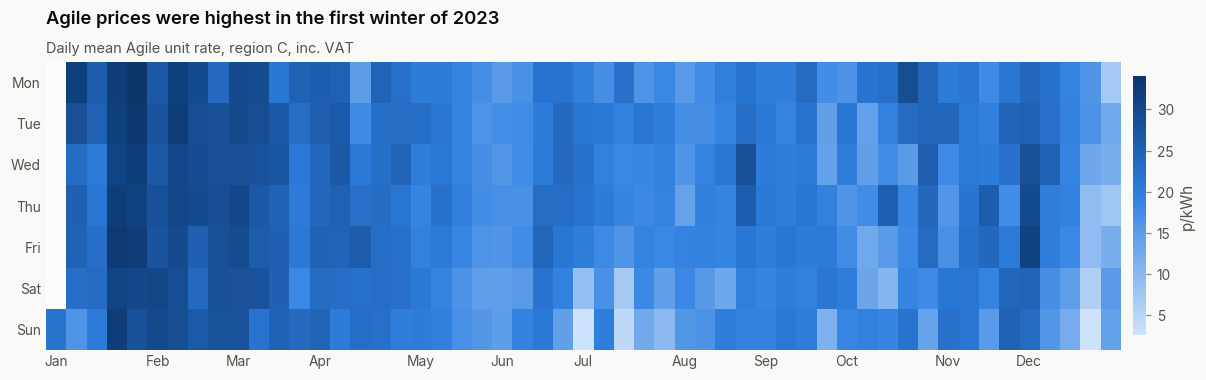

In [5]:
daily = agile.groupby(local.date).mean()
daily.index = pd.to_datetime(daily.index)
cal = pd.DataFrame({"week": ((daily.index - daily.index[0]).days + daily.index[0].weekday()) // 7,
                    "weekday": daily.index.weekday, "price": daily.values})
grid = cal.pivot(index="weekday", columns="week", values="price")
fig, ax = plt.subplots(figsize=(15, 3.4))
im = ax.imshow(grid, cmap=SEQUENTIAL_CMAP, aspect="auto")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); ax.grid(False); ax.tick_params(length=0)
month_starts = [d for d in daily.index if d.day == 1]
ax.set_xticks([((d - daily.index[0]).days + daily.index[0].weekday()) // 7 for d in month_starts],
              [d.strftime("%b") for d in month_starts])
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
cbar = fig.colorbar(im, ax=ax, pad=0.01, shrink=0.9); cbar.set_label("p/kWh"); cbar.outline.set_visible(False)
plots.title(ax, "Agile prices were highest in the first winter of 2023", f"Daily mean Agile unit rate, region {REGION}, inc. VAT")
reporter.save_fig(fig, "agile-price-calendar-2023")
plt.show()

**Use and price through the day** (Jul–Dec). Two panels on one time axis instead of a dual-axis chart. **Look for:** Agile is dearest exactly when households use most (16:00–19:00) and cheapest overnight and around midday.


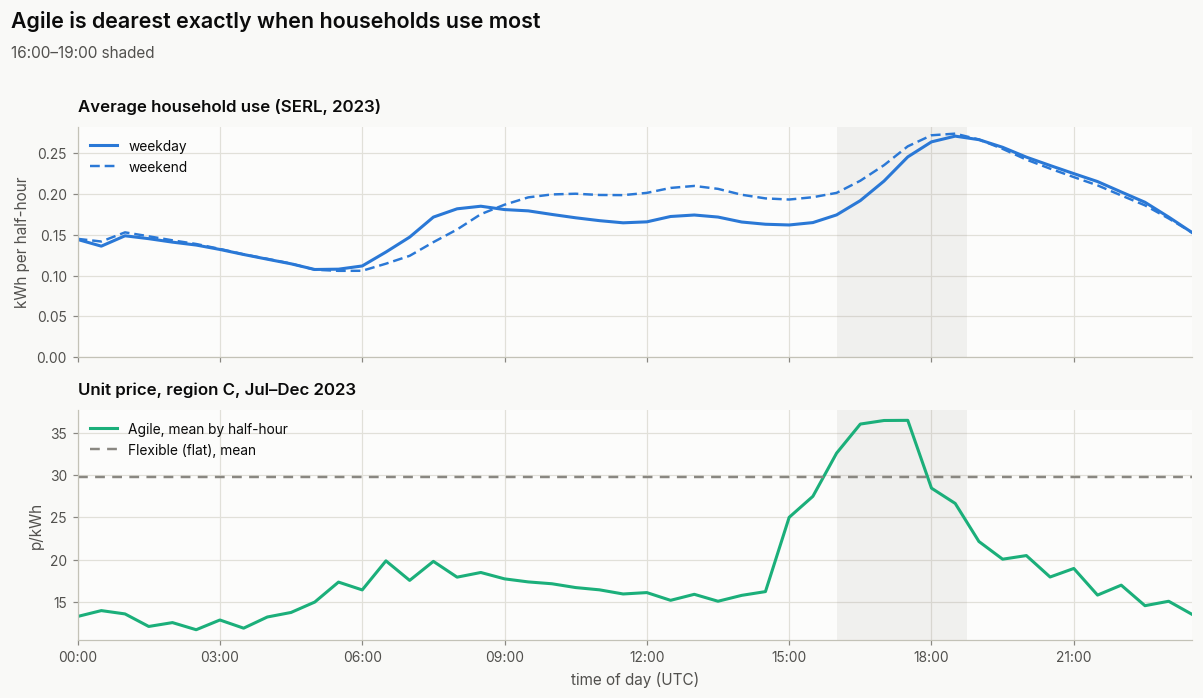

Daily use: weekday 8.39, weekend 8.77 kWh/day; peak half-hour 18:30


In [6]:
hh = serl.load_half_hourly([2023])
monthly_raw = serl.load_monthly()
profiles = {d: serl.daily_profile(hh, 2023, QUANTITY, "Wh", to_kwh=True, weekday_weekend=d) for d in ("both", "weekday", "weekend")}
level = serl.monthly_series(monthly_raw, QUANTITY, "kWh/day")
h2 = agile.index >= pd.Timestamp(H2_START, tz="UTC")
agile_by_slot = agile[h2].groupby(agile[h2].index.strftime("%H:%M")).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
for ax in axes:
    ax.axvspan(32, 37.5, color=INK["muted"], alpha=0.10, lw=0)
ax = axes[0]
ax.plot(range(48), profiles["weekday"].to_numpy(), color=COLORS["electricity"], label="weekday")
ax.plot(range(48), profiles["weekend"].to_numpy(), color=COLORS["electricity"], ls=(0, (4, 2)), lw=1.6, label="weekend")
ax.set_ylabel("kWh per half-hour"); ax.set_ylim(bottom=0); ax.legend(loc="upper left")
ax.set_title("Average household use (SERL, 2023)", loc="left", fontsize=11)
ax = axes[1]
ax.plot(range(48), agile_by_slot.to_numpy(), color=COLORS["agile"], label="Agile, mean by half-hour")
ax.axhline(flat[h2].mean(), color=COLORS["flat_tariff"], ls=(0, (4, 3)), lw=1.6, label="Flexible (flat), mean")
ax.set_ylabel("p/kWh"); ax.legend(loc="upper left")
ax.set_title(f"Unit price, region {REGION}, Jul–Dec 2023", loc="left", fontsize=11)
plots.half_hour_axis(ax); ax.set_xlabel("time of day (UTC)")
plots.figure_title(fig, "Agile is dearest exactly when households use most", "16:00–19:00 shaded")
reporter.save_fig(fig, "use-and-agile-price-by-half-hour")
plt.show()
print(f"Daily use: weekday {profiles['weekday'].sum():.2f}, weekend {profiles['weekend'].sum():.2f} kWh/day; "
      f"peak half-hour {profiles['both'].idxmax()}")

**Bills by quarter** for the average SERL household (totals include standing charges).


       total_gbp                 unit_p_per_kwh                
tariff     Agile Flexible (flat)          Agile Flexible (flat)
period                                                         
2023Q1    277.95          347.53          27.99           35.80
2023Q2    170.75          387.19          20.91           52.08
2023Q3    151.35          236.00          18.86           31.19
2023Q4    203.92          284.18          19.85           28.43

Jul–Dec 2023 (1530 kWh): Agile £355.23 vs flat £520.09 → Agile 31.7% cheaper (effective 19.43 vs 29.60 p/kWh)
Sensitivity: reading SERL times as UK clock time changes any quarterly bill by at most £2.46


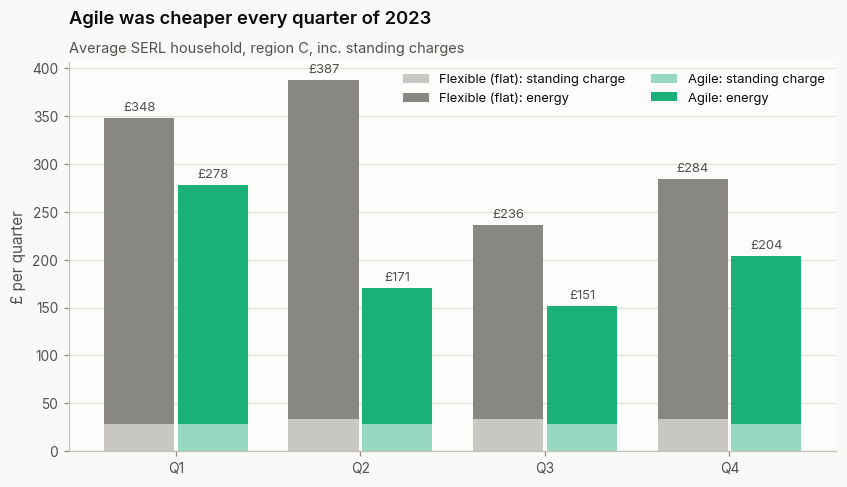

In [7]:
idx = tariffs.half_hour_index(START, END)
by_reading = {}
for label, utc in (("UTC (assumed)", True), ("UK clock time", False)):
    k = tariffs.build_consumption(profiles, level, idx, profile_time_is_utc=utc)
    by_reading[label] = tariffs.compare(k, TARIFFS, by="Q").pivot(index="period", columns="tariff", values="total_gbp")

kwh = tariffs.build_consumption(profiles, level, idx, profile_time_is_utc=True)
quarterly = tariffs.compare(kwh, TARIFFS, by="Q")
print(quarterly.pivot(index="period", columns="tariff", values=["total_gbp", "unit_p_per_kwh"]).round(2).to_string())
reporter.save_table(quarterly, "tariff_quarterly_bills")

h2_kwh = kwh[kwh.index >= pd.Timestamp(H2_START, tz="UTC")]
b_agile = tariffs.bill(h2_kwh, agile, standing_agile)
b_flat = tariffs.bill(h2_kwh, flat, standing_flat)
print(f"\nJul–Dec 2023 ({b_agile['kwh']:.0f} kWh): Agile £{b_agile['total_gbp']:.2f} vs flat £{b_flat['total_gbp']:.2f} "
      f"→ Agile {100 * (1 - b_agile['total_gbp'] / b_flat['total_gbp']):.1f}% cheaper "
      f"(effective {b_agile['unit_p_per_kwh']:.2f} vs {b_flat['unit_p_per_kwh']:.2f} p/kWh)")
diff = (by_reading["UK clock time"] - by_reading["UTC (assumed)"]).abs().max().max()
print(f"Sensitivity: reading SERL times as UK clock time changes any quarterly bill by at most £{diff:.2f}")

q = quarterly.pivot(index="period", columns="tariff", values=["energy_gbp", "standing_gbp"])
fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(q))
for off, name, color in ((-0.2, "Flexible (flat)", COLORS["flat_tariff"]), (0.2, "Agile", COLORS["agile"])):
    e, s = q[("energy_gbp", name)], q[("standing_gbp", name)]
    ax.bar(x + off, s, width=0.38, color=color, alpha=0.45, label=f"{name}: standing charge")
    bars = ax.bar(x + off, e, width=0.38, bottom=s, color=color, label=f"{name}: energy")
    plots.bar_labels(ax, bars, fmt="£{:.0f}", labels=[f"£{v:.0f}" for v in e + s])
ax.set_xticks(x, [p.replace("2023", "") for p in q.index]); ax.set_ylabel("£ per quarter")
ax.grid(axis="x", visible=False); ax.legend(loc="upper right", fontsize=8.5, ncols=2)
plots.title(ax, "Agile was cheaper every quarter of 2023", f"Average SERL household, region {REGION}, inc. standing charges")
reporter.save_fig(fig, "quarterly-bills-2023")
plt.show()

**Load shifting on Agile** (Jul–Dec): move part of the 16:00–19:00 (UK time) use into each day's 8 cheapest half-hours. The waterfall runs from the flat bill to Agile, then each extra 10% shifted. The shares are assumptions, not measured behaviour.


Average SERL household, Jul–Dec 2023, region C (flat bill £520.09)
 shifted_from_peak_pct  agile_bill_gbp  saving_vs_no_shift_gbp  saving_vs_flat_gbp  effective_p_per_kwh  peak_window_kwh
                     0          355.23                    0.00              164.86                19.43           230.26
                    10          349.75                    5.48              170.34                19.07           207.23
                    20          344.27                   10.96              175.82                18.71           184.21
                    30          338.79                   16.44              181.30                18.35           161.18


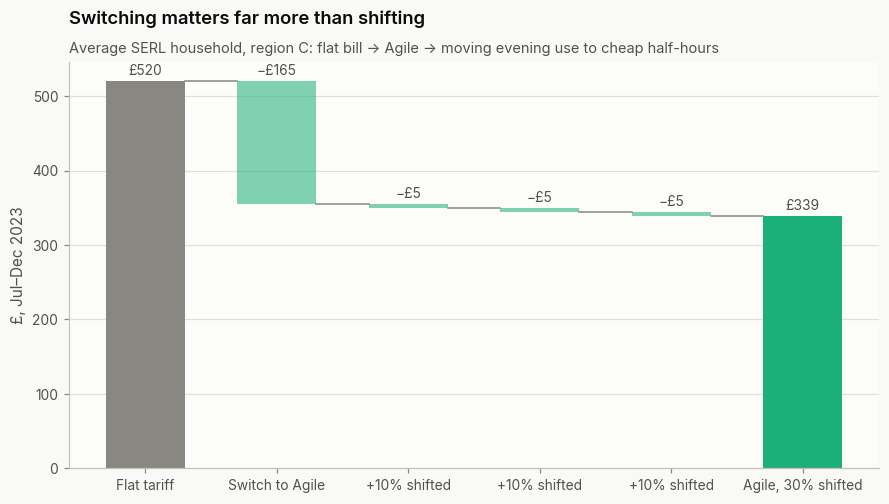

In [8]:
peak_local = h2_kwh.index.tz_convert(tariffs.UK_TZ).strftime("%H:%M")
in_peak = (peak_local >= "16:00") & (peak_local < "19:00")
rows = []
for frac in (0.0, 0.1, 0.2, 0.3):
    shifted = tariffs.shift_peak(h2_kwh, agile, frac)
    b = tariffs.bill(shifted, agile, standing_agile)
    rows.append({"shifted_from_peak_pct": round(100 * frac), "agile_bill_gbp": b["total_gbp"],
                 "saving_vs_no_shift_gbp": b_agile["total_gbp"] - b["total_gbp"],
                 "saving_vs_flat_gbp": b_flat["total_gbp"] - b["total_gbp"],
                 "effective_p_per_kwh": b["unit_p_per_kwh"], "peak_window_kwh": shifted[in_peak].sum()})
shift_table = pd.DataFrame(rows)
print(f"Average SERL household, Jul–Dec 2023, region {REGION} (flat bill £{b_flat['total_gbp']:.2f})")
print(shift_table.round(2).to_string(index=False))
reporter.save_table(shift_table, "tariff_load_shift_h2_2023")

steps = [("Flat tariff", b_flat["total_gbp"])]
steps.append(("Switch to Agile", b_agile["total_gbp"] - b_flat["total_gbp"]))
prev = b_agile["total_gbp"]
for _, r in shift_table.iloc[1:].iterrows():
    steps.append((f"+10% shifted", r["agile_bill_gbp"] - prev)); prev = r["agile_bill_gbp"]
steps.append(("Agile, 30% shifted", prev))
fig, ax = plt.subplots(figsize=(9.5, 4.8))
running = 0
for i, (name, v) in enumerate(steps):
    total = i in (0, len(steps) - 1)
    bottom = 0 if total else running + min(v, 0)
    color = COLORS["flat_tariff"] if i == 0 else COLORS["agile"] if total else COLORS["agile"]
    ax.bar(i, abs(v) if not total else v, bottom=bottom, color=color, alpha=1 if total else 0.55, width=0.6)
    ax.annotate(f"£{v:.0f}" if total else f"−£{abs(v):.0f}", (i, bottom + (v if total else abs(v))), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=9, color=INK["secondary"])
    running = v if total else running + v
    if i < len(steps) - 1:
        ax.plot([i + 0.3, i + 0.7], [running, running], color=INK["muted"], lw=1)
ax.set_xticks(range(len(steps)), [s[0] for s in steps]); ax.set_ylabel("£, Jul–Dec 2023"); ax.grid(axis="x", visible=False)
plots.title(ax, "Switching matters far more than shifting",
            f"Average SERL household, region {REGION}: flat bill → Agile → moving evening use to cheap half-hours")
reporter.save_fig(fig, "load-shift-waterfall")
plt.show()

### Who benefits? Household groups (Jul–Dec 2023, region C prices for everyone)

SERL gives weekday/weekend profiles only for the whole sample, so each group uses its all-days profile. A group is kept only if its July–December months and profile rest on at least 50 households. Groups linked to energy poverty are red, comparators violet. **Look for:** every group saves about a third; the most deprived save slightly less per kWh.


           group_label       role  households  kwh_per_day  peak_share_pct  flat_gbp  agile_gbp  agile_saving_pct  agile_p_per_kwh  extra_saving_shift20_gbp
        All households      other        9080         8.31           15.04    519.89     355.45             31.63            19.45                     10.95
                    PV      other         600         8.77           12.92    541.22     358.72             33.72            18.65                     10.08
                 No PV      other        8480         8.28           15.20    518.67     355.36             31.49            19.51                     11.02
           Gas heating      other        7220         7.84           15.43    494.92     340.71             31.16            19.59                     10.58
      Electric heating      other         500        11.78           12.60    702.41     459.13             34.63            18.50                     13.17
 IMD 1 (most deprived) vulnerable        1810         6.95

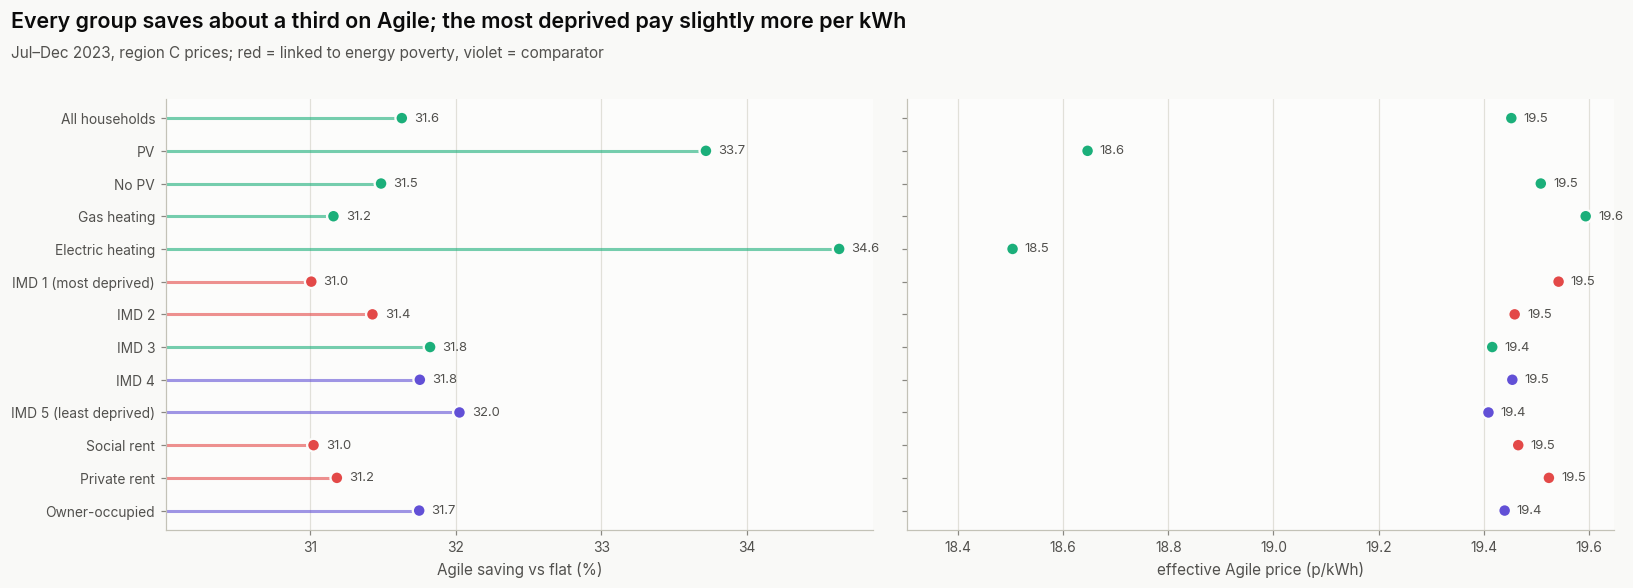

In [9]:
GROUPS = [({}, "", "")] + [({"pv": v}, "", "") for v in ("Yes", "No")] + [({"fuel": v}, "", "") for v in ("Gas", "Electric")]
GROUPS += [({"segment": "IMD_quintile", "segment_value": q}, "IMD_quintile", q) for q in "12345"]
GROUPS += [({"segment": "tenure", "segment_value": t}, "tenure", t) for t in ("Social rent", "Private rent", "Own outright or mortgage")]

h2_idx = tariffs.half_hour_index(H2_START, END)
rows = []
for filt, seg, val in GROUPS:
    label = group_label(seg or None, val or None, fuel=filt.get("fuel", "All"), pv=filt.get("pv", "All"))
    prof = serl.daily_profile(hh, 2023, QUANTITY, "Wh", to_kwh=True, **filt)
    lvl = serl.monthly_series(monthly_raw, QUANTITY, "kWh/day", **filt)
    n = min(serl.monthly_series(monthly_raw, QUANTITY, "kWh/day", value="n_rounded", **filt).loc[H2_START:"2023-12"].min(),
            serl.select_slice(hh, QUANTITY, "Wh", **filt)["n_rounded"].min())
    if n < MIN_HOUSEHOLDS:
        print(f"skipped {label}: only {int(n)} households")
        continue
    g_kwh = tariffs.build_consumption({"both": prof}, lvl, h2_idx)
    ba, bf = tariffs.bill(g_kwh, agile, standing_agile), tariffs.bill(g_kwh, flat, standing_flat)
    bs = tariffs.bill(tariffs.shift_peak(g_kwh, agile, 0.2), agile, standing_agile)
    t = g_kwh.index.tz_convert(tariffs.UK_TZ).strftime("%H:%M")
    rows.append({"group_label": label, "role": role(seg, val) if seg else "other", "households": int(n),
                 "kwh_per_day": g_kwh.sum() / 184,
                 "peak_share_pct": 100 * g_kwh[(t >= "16:00") & (t < "19:00")].sum() / g_kwh.sum(),
                 "flat_gbp": bf["total_gbp"], "agile_gbp": ba["total_gbp"],
                 "agile_saving_pct": 100 * (1 - ba["total_gbp"] / bf["total_gbp"]),
                 "agile_p_per_kwh": ba["unit_p_per_kwh"], "extra_saving_shift20_gbp": ba["total_gbp"] - bs["total_gbp"]})
group_table = pd.DataFrame(rows)
print(group_table.round(2).to_string(index=False))
reporter.save_table(group_table, "tariff_groups_h2_2023")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
g = group_table.iloc[::-1]
pos = np.arange(len(g))
colors = [ROLE_COLORS[r] if r != "other" else COLORS["agile"] for r in g["role"]]
for ax, col, xlabel in ((axes[0], "agile_saving_pct", "Agile saving vs flat (%)"),
                        (axes[1], "agile_p_per_kwh", "effective Agile price (p/kWh)")):
    lo = g[col].min() - (1 if col == "agile_saving_pct" else 0.2)
    if col == "agile_saving_pct":      # stems only where the axis is a meaningful baseline comparison
        ax.hlines(pos, lo, g[col], color=colors, lw=2, alpha=0.6)
    ax.scatter(g[col], pos, color=colors, s=70, zorder=3, edgecolor=COLORS["surface"], linewidth=1.5)
    for p, v in zip(pos, g[col]):
        ax.annotate(f"{v:.1f}", (v, p), xytext=(8, 0), textcoords="offset points", va="center", fontsize=8.5,
                    color=INK["secondary"])
    ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False); ax.set_xlim(left=lo)
axes[0].set_yticks(pos, g["group_label"])
plots.figure_title(fig, "Every group saves about a third on Agile; the most deprived pay slightly more per kWh",
                   f"Jul–Dec 2023, region {REGION} prices; red = linked to energy poverty, violet = comparator")
reporter.save_fig(fig, "agile-saving-by-group")
plt.show()

### By region: each region's own consumption and its own prices

Each SERL region's 2023 profile and monthly levels are priced with the Agile and Flexible rates of the matching distribution (GSP) region. The mapping is approximate where boundaries differ: Wales → South Wales (K), Scotland → South Scotland (N), South East → South Eastern (J).


Jul–Dec 2023, each region with its own prices
         region gsp_region  kwh_per_day  flat_p_per_kwh  agile_p_per_kwh  flat_gbp  agile_gbp  agile_saving_pct  extra_saving_shift20_gbp
 Greater London          C         8.26           29.58            19.19    516.78     349.61             32.35                     10.03
East of England          A         8.59           29.10            20.43    537.14     391.49             27.12                     11.98
     North West          G         8.10           28.37            20.50    514.52     382.18             25.72                     11.33
  East Midlands          B         8.34           27.91            19.85    517.64     385.65             25.50                     12.21
     South East          J         8.91           29.29            21.06    564.18     420.84             25.41                     11.85
      Yorkshire          M         8.18           27.69            19.76    515.92     385.51             25.28               

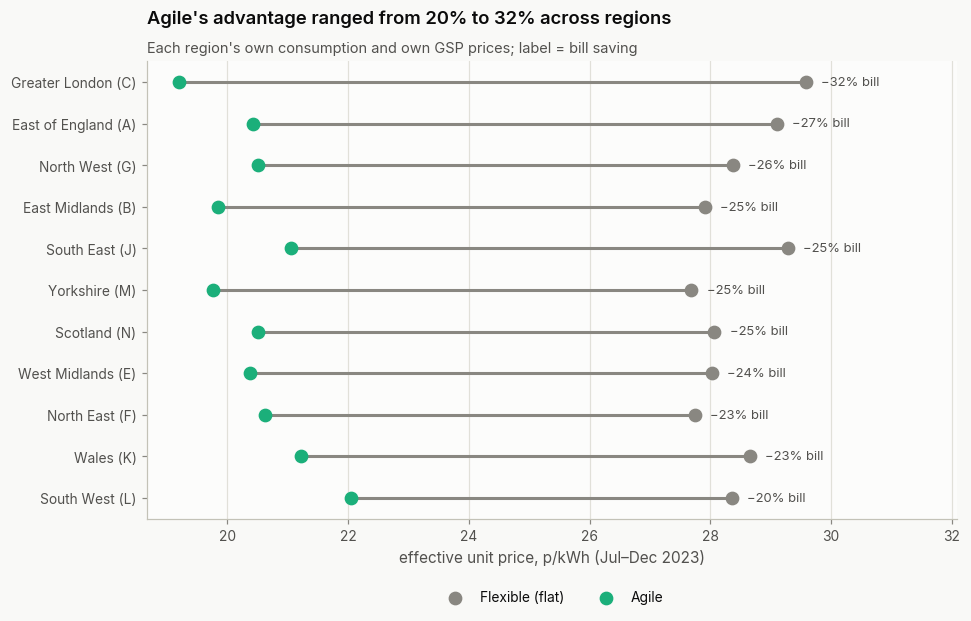

In [10]:
GSP_REGION = {"East of England": "A", "East Midlands": "B", "Greater London": "C", "West Midlands": "E",
              "North East": "F", "North West": "G", "South East": "J", "Wales": "K", "South West": "L",
              "Yorkshire": "M", "Scotland": "N"}
rows = []
for region, letter in GSP_REGION.items():
    ag = tariffs.half_hourly_rates(tariffs.fetch_unit_rates(tariffs.AGILE_PRODUCT, tariffs.agile_code(letter), START, END), START, END)
    fl = tariffs.half_hourly_rates(tariffs.fetch_unit_rates(tariffs.FLEX_PRODUCT, tariffs.flex_code(letter), START, END), START, END)
    s_ag = tariffs.daily_standing_charges(tariffs.fetch_standing_charges(tariffs.AGILE_PRODUCT, tariffs.agile_code(letter), START, END), START, END)
    s_fl = tariffs.daily_standing_charges(tariffs.fetch_standing_charges(tariffs.FLEX_PRODUCT, tariffs.flex_code(letter), START, END), START, END)
    filt = {"segment": "region", "segment_value": region}
    prof = serl.daily_profile(hh, 2023, QUANTITY, "Wh", to_kwh=True, **filt)
    r_kwh = tariffs.build_consumption({"both": prof}, serl.monthly_series(monthly_raw, QUANTITY, "kWh/day", **filt), h2_idx)
    ba, bf = tariffs.bill(r_kwh, ag, s_ag), tariffs.bill(r_kwh, fl, s_fl)
    bs = tariffs.bill(tariffs.shift_peak(r_kwh, ag, 0.2), ag, s_ag)
    rows.append({"region": region, "gsp_region": letter, "kwh_per_day": r_kwh.sum() / 184,
                 "flat_p_per_kwh": bf["unit_p_per_kwh"], "agile_p_per_kwh": ba["unit_p_per_kwh"],
                 "flat_gbp": bf["total_gbp"], "agile_gbp": ba["total_gbp"],
                 "agile_saving_pct": 100 * (1 - ba["total_gbp"] / bf["total_gbp"]),
                 "extra_saving_shift20_gbp": ba["total_gbp"] - bs["total_gbp"]})
region_table = pd.DataFrame(rows).sort_values("agile_saving_pct", ascending=False)
print("Jul–Dec 2023, each region with its own prices")
print(region_table.round(2).to_string(index=False))
reporter.save_table(region_table, "tariff_regions_h2_2023")

fig, ax = plt.subplots(figsize=(9.5, 5.4))
r = region_table.iloc[::-1]
pos = np.arange(len(r))
ax.hlines(pos, r["agile_p_per_kwh"], r["flat_p_per_kwh"], color=INK["muted"], lw=2)
ax.scatter(r["flat_p_per_kwh"], pos, color=COLORS["flat_tariff"], s=64, zorder=3, label="Flexible (flat)")
ax.scatter(r["agile_p_per_kwh"], pos, color=COLORS["agile"], s=64, zorder=3, label="Agile")
for p, (_, row) in zip(pos, r.iterrows()):
    ax.annotate(f"−{row['agile_saving_pct']:.0f}% bill", (row["flat_p_per_kwh"], p), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=INK["secondary"])
ax.set_yticks(pos, [f"{n} ({g})" for n, g in zip(r["region"], r["gsp_region"])]); ax.grid(axis="y", visible=False)
ax.set_xlabel("effective unit price, p/kWh (Jul–Dec 2023)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncols=2)
ax.set_xlim(right=r["flat_p_per_kwh"].max() + 2.5)
plots.title(ax, "Agile's advantage ranged from 20% to 32% across regions",
            "Each region's own consumption and own GSP prices; label = bill saving")
reporter.save_fig(fig, "agile-vs-flat-by-region")
plt.show()

## Conclusions

- **Gas follows the weather:** each extra heating degree-day adds about 5.2 kWh/day of gas (94% HDI 5.1–5.4, R² 0.92); regions differ only a little at the same weather.
- **Monthly electricity is easy to predict but hard to beat:** gradient boosting is best for 2023 (MAE 0.40 kWh/day) but only just beats repeating last year's month (0.41); tree models over-forecast because they cannot extrapolate the downward trend.
- **Agile was about 32% cheaper than the flat tariff in Jul–Dec 2023** for the average London household (20–32% across regions), because wholesale prices fell while the price cap lagged.
- **Switching matters more than shifting:** moving 20% of evening use to cheap hours saves about £11 more per half-year, against about £165 from switching.
- **Every group benefits, the most deprived slightly less:** IMD 1 saves 31.0% vs 32.0% for IMD 5 and pays slightly more per kWh, because more of its use falls in the dear evening window.

## Limitations

- 2023 conditions (falling wholesale prices, lagging cap) favour Agile; 4.2 shows the 2022 crisis reversed this.
- Load-shifting shares are assumptions; households' ability to shift is not measured.
- Group comparisons use one region's prices for everyone; the daily shape is an annual average.
